In [ ]:
# ----------------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# ----------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm, skew, spearmanr, qmc
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures Settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [ ]:
# ----------------------------------------------------------------------------
# 1. Data 
# ----------------------------------------------------------------------------
X = np.load('..\Function_4_Data\Week_11_Data/F4_Week_11_inputs.npy')
y = np.load('..\Function_4_Data\Week_11_Data/F4_Week_11_outputs.npy')
n, d = X.shape
N_INITIAL = 30
best = int(np.argmax(y))
xb = X[best]
dist = np.linalg.norm(X - xb, axis=1)
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[-1], 6)}, y = {y[-1]:.6f}")
print(f"Best observed: row {best}, x = {np.round(xb, 6)}, y = {y[best]:.6f}")


n = 40 (30 initial + 10 queried); newest x = [0.440781 0.366185 0.403976 0.444117], y = 0.089284
best observed: row 37, x = [0.422604 0.372638 0.406408 0.426606], y = 0.615945


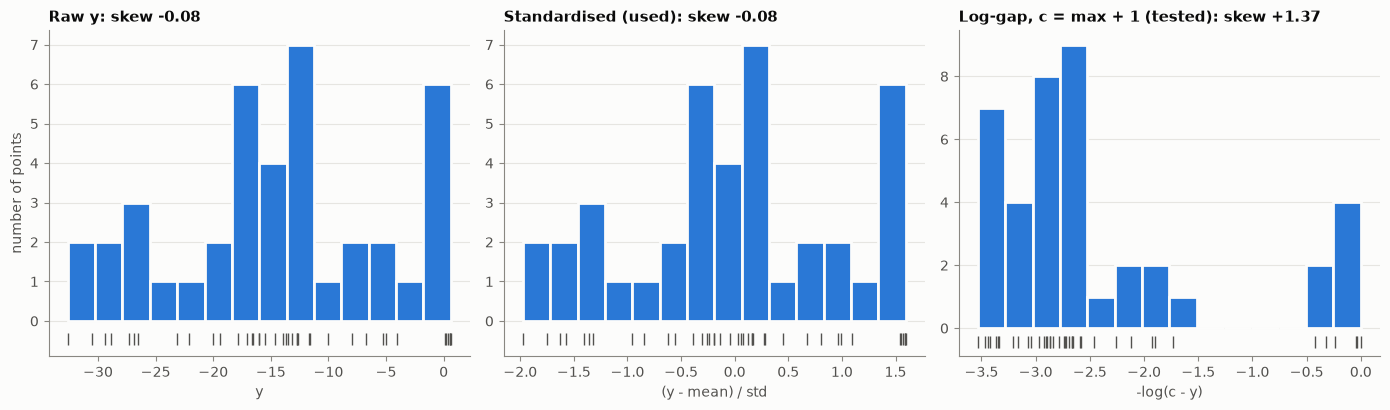

In [25]:
# ----------------------------------------------------------------------------
# 2. Data transformation + before/after plot
# ----------------------------------------------------------------------------

def t_std(v):
    return (v - v.mean()) / v.std(), lambda m: m * v.std() + v.mean()
def t_loggap(v, gap):
    c = v.max() + gap
    return -np.log(c - v), lambda m: c - np.exp(-m)
TRANSFORMS = {"standardised": t_std(y), "log-gap (c = max + 1)": t_loggap(y, 1.0),
              "log-gap (c = max + 0.3)": t_loggap(y, 0.3)}

def fit(t, ard=True):
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=[0.3] * d if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e1), nu=2.5)
         + WhiteKernel(1e-4, (1e-10, 1e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, n_restarts_optimizer=20,
                                    random_state=SEED).fit(X, t)


# Fig 1: target distribution
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, v, xl) in zip(axes, [("Raw y", y, "y"),
                                     ("Standardised (used)", TRANSFORMS["standardised"][0], "(y - mean) / std"),
                                     ("Log-gap, c = max + 1 (tested)", TRANSFORMS["log-gap (c = max + 1)"][0], "-log(c - y)")]):
    ax.hist(v, bins=14, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.45), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(f"{title}: skew {skew(v):+.2f}"); ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of points")
fig.tight_layout()


MODELS (LOO-CV)
  standardised, ARD                ls=[1.366 1.509 1.37  1.369]  noise sd (y)=0.196  LOO RMSE/std=0.157  Spearman=0.983  top-6 raw RMSE=0.257  top-6 Spearman=-0.77
  standardised, isotropic          ls=[1.36]  noise sd (y)=0.196  LOO RMSE/std=0.163  Spearman=0.982  top-6 raw RMSE=0.258  top-6 Spearman=-0.77


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  log-gap (c = max + 1), ARD       ls=[ 0.268 10.     0.323  0.376]  noise sd (y)=1.303  LOO RMSE/std=0.264  Spearman=0.810  top-6 raw RMSE=0.251  top-6 Spearman=-0.89


c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Ilias\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  log-gap (c = max + 0.3), ARD     ls=[ 0.097 10.     0.194 10.   ]  noise sd (y)=2.009  LOO RMSE/std=0.347  Spearman=0.653  top-6 raw RMSE=0.234  top-6 Spearman=-0.94


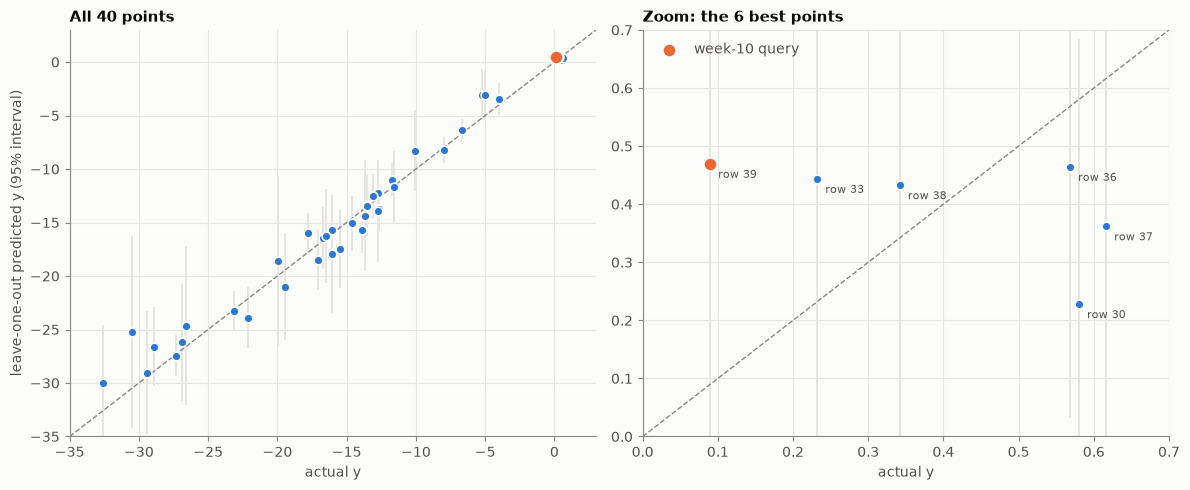

In [26]:
# ----------------------------------------------------------------------------
# 3. Surrogate: re-check isotropic vs ARD on all points
# ----------------------------------------------------------------------------

def loo(gp, t):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True).fit(X[keep], t[keep])
        a, s = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], s[0]
    return mu, sd

top = np.argsort(-y)[:6]
models, loos = {}, {}
print("\nMODELS (LOO-CV)")
for tname, (t, back) in TRANSFORMS.items():
    for ard in ((True, False) if tname == "standardised" else (True,)):
        key = f"{tname}, {'ARD' if ard else 'isotropic'}"
        gp = fit(t, ard)
        mu, sd = loo(gp, t)
        models[key], loos[key] = (gp, t, back), (mu, sd)
        yb = back(mu)
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:32s} ls={np.round(ls, 3)}  noise sd (y)={np.sqrt(gp.kernel_.k2.noise_level) * y.std():.3f}  "
              f"LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  Spearman={spearmanr(t, mu)[0]:.3f}  "
              f"top-6 raw RMSE={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.3f}  "
              f"top-6 Spearman={spearmanr(y[top], yb[top])[0]:+.2f}")
REC = "standardised, ARD"
gp, t, back = models[REC]


# Fig 2: LOO, full range and the top-6 zoom
mu, sd = loos[REC]
yb, sb = back(mu), sd * y.std()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (lim, title) in zip(axes, [((-35, 3), "All 40 points"), ((0.0, 0.7), "Zoom: the 6 best points")]):
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(y, yb, yerr=1.96 * sb, fmt="none", ecolor=GRIDC, elinewidth=1.5, zorder=1)
    ax.scatter(y, yb, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[-1], yb[-1], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="week-10 query")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y"); ax.set_title(title)
axes[0].set_ylabel("leave-one-out predicted y (95% interval)")
axes[1].legend(frameon=False, loc="upper left", labelcolor=INK2)
for i in top:
    axes[1].annotate(f"row {i}", (y[i], yb[i]), xytext=(6, -10), textcoords="offset points", fontsize=8, color=INK2)
fig.tight_layout()

In [27]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

S = qmc.Sobol(d, seed=1).random(2 ** 14)
lo, hi = np.clip(xb - 0.12, 0, 1), np.clip(xb + 0.12, 0, 1)
Z = lo + S * (hi - lo)
x0 = Z[gp.predict(Z).argmax()]
x_pm = minimize(lambda q: -gp.predict(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B").x
GOOD = [30, 36, 37]
cands = {
    "A: EI, Week-10": np.array([0.407917, 0.413882, 0.409942, 0.407179]),
    "B: highest GP mean (±0.12 box)": x_pm,
    "C: centroid of the 3 best points": X[GOOD].mean(axis=0),
    "Reference: best observed point": xb,
}
print("=" * 100)
print("CANDIDATES: predicted y by each model")
print("=" * 100)
for name, xc in cands.items():
    preds = {k: v[2](v[0].predict(xc[None]))[0] for k, v in models.items()}
    m, s = gp.predict(xc[None], return_std=True)
    print(f"  {name:34s} x = ({', '.join(f'{q:.6f}' for q in xc)})  dist {np.linalg.norm(xc - xb):.3f}  "
          f"{REC} = {back(m)[0]:.3f} +/- {s[0] * y.std():.3f}  "
          + "  ".join(f"{k.split(',')[0]}={v:.3f}" for k, v in preds.items() if k != REC))
    dmin = np.min(np.linalg.norm(X[[33, 38, 39]] - xc, axis=1))
    print(f"      nearest poor point (rows 33, 38, 39) at distance {dmin:.3f}")

CANDIDATES: predicted y by each model
  A: EI, Week-10                     x = (0.407917, 0.413882, 0.409942, 0.407179)  dist 0.048  standardised, ARD = 0.486 +/- 0.249  standardised=0.476  log-gap (c = max + 1)=0.428  log-gap (c = max + 0.3)=0.396
      nearest poor point (rows 33, 38, 39) at distance 0.049
  B: highest GP mean (±0.12 box)     x = (0.414851, 0.402510, 0.402832, 0.415633)  dist 0.033  standardised, ARD = 0.510 +/- 0.226  standardised=0.506  log-gap (c = max + 1)=0.433  log-gap (c = max + 0.3)=0.441
      nearest poor point (rows 33, 38, 39) at distance 0.038
  C: centroid of the 3 best points   x = (0.423958, 0.386428, 0.392013, 0.421939)  dist 0.021  standardised, ARD = 0.470 +/- 0.213  standardised=0.471  log-gap (c = max + 1)=0.418  log-gap (c = max + 0.3)=0.459
      nearest poor point (rows 33, 38, 39) at distance 0.030
  Reference: best observed point     x = (0.422604, 0.372638, 0.406408, 0.426606)  dist 0.000  standardised, ARD = 0.427 +/- 0.220  standardised=0

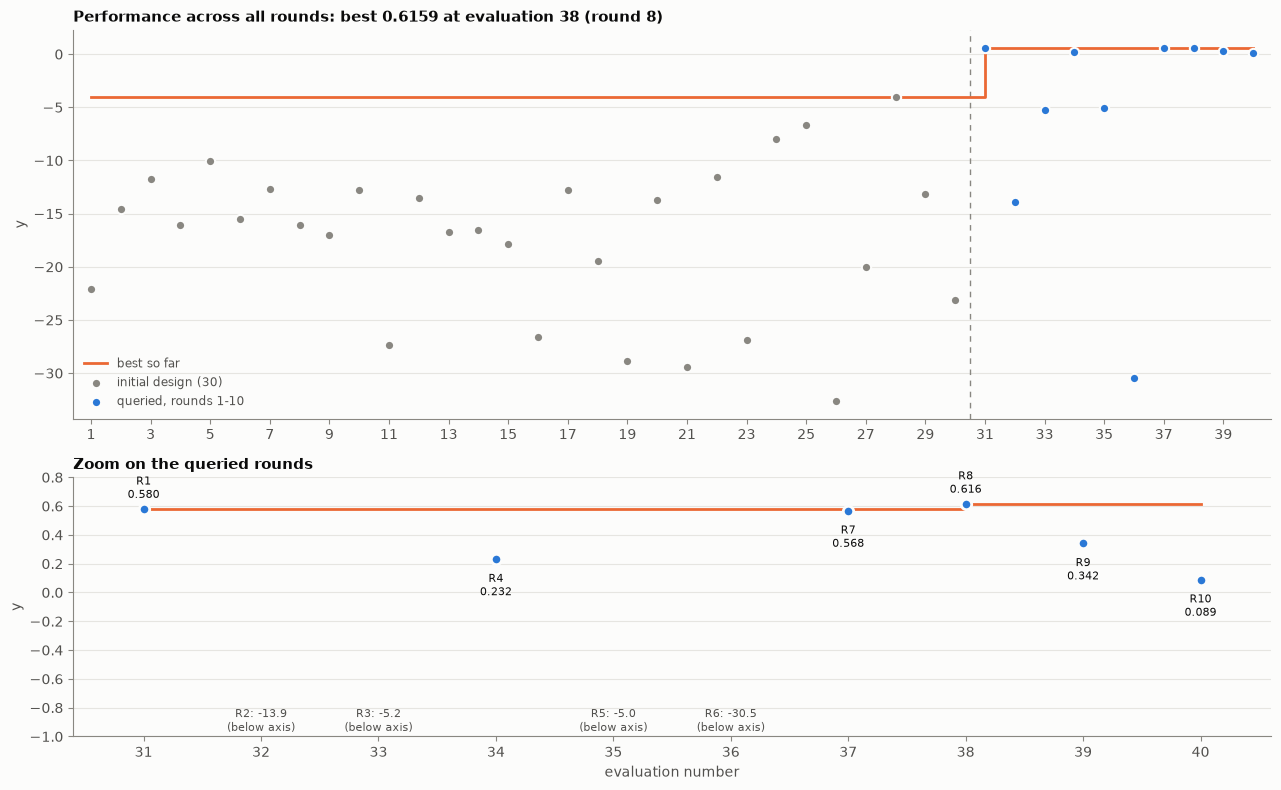

In [28]:
# Fig 5: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(13, 8), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=45, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=45, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
ax.set_xticks(idx[::2]); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
for i in q:
    if y[i] >= -1:
        az.scatter(idx[i], y[i], s=56, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.1f}\n(below axis)", (idx[i], -1), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(-1, 0.8); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout()